# Sidewalk Robot vs. DoorDash Driver

**Question:** when does a 3.5 mph sidewalk robot beat a car driving 25 mph?

The answer has two halves:

1. **Trip economics.** This half is closed form. Time and cost are both linear
   in distance, so you can solve for the distance where the two options cost
   the same. Rain changes the slopes.
2. **Navigation.** This half is a simulation. The robot has to stay on a sidewalk
   about 2 m wide while its GPS error is a few meters. The question is how a PID
   loop plus sensor fusion manages that, and where it fails.

Everything runs through [`dgs/delivery_robot_vs_driver.py`](../dgs/delivery_robot_vs_driver.py),
which reuses [`dgs/pid_controller.PIDController`](../dgs/pid_controller.py).

> **Assumptions, stated up front.** The default speeds and costs are
> order-of-magnitude guesses. They are *not* figures from Starship, DoorDash,
> or anyone else. The structure of the results (linear costs, a crossover,
> the bias that fusion can't remove) does not depend on these numbers.
> The crossover location does, so change them and rerun.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import asdict

from dgs.delivery_robot_vs_driver import (
    ROBOT, DRIVER, MODES, GPS_OPEN_SKY, GPS_URBAN_CANYON, MPH_TO_MS,
    trip_time_min, trip_cost, cost_line, crossover_distance,
    monte_carlo_trip_times, gps_error, simulate_path_following, with_rain,
)

for c in (ROBOT, DRIVER):
    print(c.name)
    for k, v in asdict(c).items():
        if k != "name":
            print(f"   {k:18s} {v}")

sidewalk robot
   speed_mph          3.5
   overhead_min       2.0
   cost_fixed         1.5
   cost_per_mile      0.05
   cost_per_hour      3.0
   max_range_mi       3.0
   rain_speed_factor  0.75
   rain_cost_factor   1.0
   rain_availability  0.6
human driver
   speed_mph          15.0
   overhead_min       6.0
   cost_fixed         2.5
   cost_per_mile      0.67
   cost_per_hour      20.0
   max_range_mi       inf
   rain_speed_factor  0.85
   rain_cost_factor   1.3
   rain_availability  1.0


# Part 1: Trip time

$$t(d) = t_0 + \frac{60\,d}{v\,f_\text{rain}} \quad[\text{min}]$$

$t_0$ is the fixed overhead per trip. For a car it's large: parking, walking up,
waiting at the door. For a robot it's small, because the customer walks out to it.
The slope $60/v$ is large for the robot.

So the car's line starts higher and is flatter. The two lines cross at
$d_t = \dfrac{t_{0,\text{car}}-t_{0,\text{robot}}}{60/v_\text{robot}-60/v_\text{car}}$.

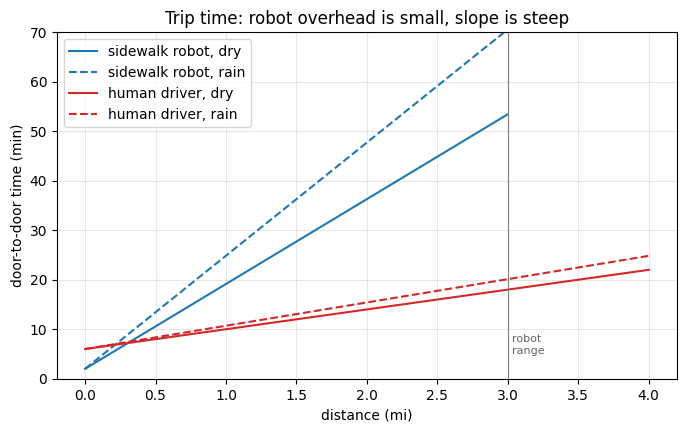

time crossover (dry): 0.30 mi = 490 m


In [2]:
d = np.linspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
for c, col in ((ROBOT, "C0"), (DRIVER, "C3")):
    ax.plot(d, trip_time_min(c, d), col, label=f"{c.name}, dry")
    ax.plot(d, trip_time_min(c, d, rain=True), col, ls="--", label=f"{c.name}, rain")
ax.axvline(ROBOT.max_range_mi, color="0.5", lw=0.8)
ax.text(ROBOT.max_range_mi + 0.03, 5, "robot\nrange", color="0.4", fontsize=8)
ax.set(xlabel="distance (mi)", ylabel="door-to-door time (min)", ylim=(0, 70),
       title="Trip time: robot overhead is small, slope is steep")
ax.legend(); ax.grid(alpha=0.3); plt.show()

d_t = (DRIVER.overhead_min - ROBOT.overhead_min) / (60/ROBOT.speed_mph - 60/DRIVER.speed_mph)
print(f"time crossover (dry): {d_t:.2f} mi = {d_t*1609.344:.0f} m")

The robot is only faster for trips shorter than about a third of a mile,
about 500 m, roughly a single campus. Past that, the car wins on time at every distance.
So the robot's case can't rest on speed. It has to rest on **cost**.

# Part 2: Cost, and the value of the customer's time

Operator cost per trip:

$$C_\text{op}(d) = k_\text{rain}\Big[c_\text{fixed} + c_\text{mile}\,d + c_\text{hour}\,\tfrac{t(d)}{60}\Big]$$

That alone ignores the customer. Food that arrives in 40 minutes instead of 12 is
worth less. Model this with a **value of time** (VOT, in \$ per minute of waiting)
to get a *generalized cost*:

$$G(d) = C_\text{op}(d) + \text{VOT}\cdot t(d) = a + b\,d$$

$G$ is still linear in $d$, so the crossover is a single division:

$$\boxed{d^\* = \frac{a_\text{driver} - a_\text{robot}}{b_\text{robot} - b_\text{driver}}}$$

The robot wins for $d < d^\*$ because it has the lower intercept and the steeper
slope.

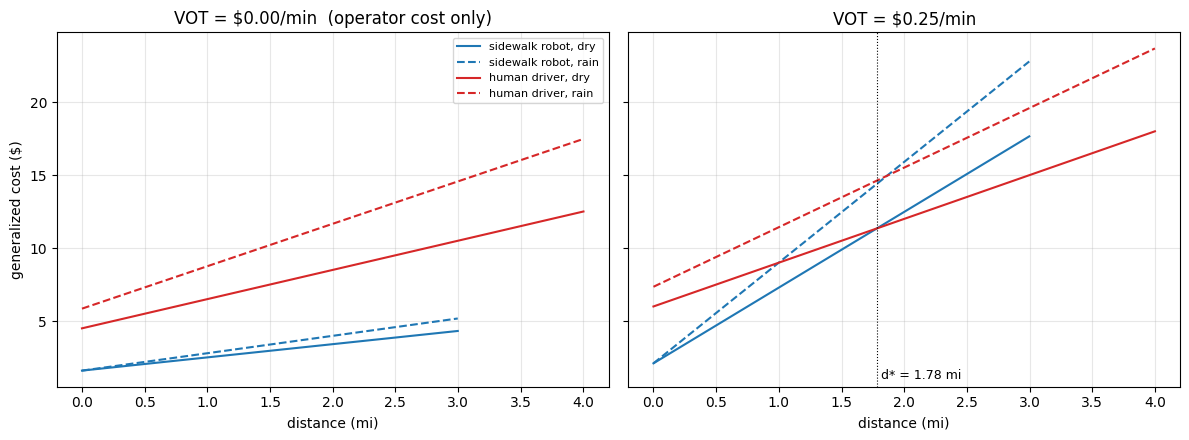

rain=False  VOT=$0.00/min  ->  d* = nan mi
rain=False  VOT=$0.10/min  ->  d* = 15.13 mi
rain=False  VOT=$0.25/min  ->  d* = 1.78 mi
rain=False  VOT=$0.50/min  ->  d* = 0.89 mi
rain=True   VOT=$0.00/min  ->  d* = nan mi
rain=True   VOT=$0.10/min  ->  d* = 47.56 mi
rain=True   VOT=$0.25/min  ->  d* = 1.86 mi
rain=True   VOT=$0.50/min  ->  d* = 0.85 mi


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, vot in zip(axes, (0.0, 0.25)):
    for c, col in ((ROBOT, "C0"), (DRIVER, "C3")):
        ax.plot(d, trip_cost(c, d, value_of_time=vot), col, label=f"{c.name}, dry")
        ax.plot(d, trip_cost(c, d, rain=True, value_of_time=vot), col, ls="--",
                label=f"{c.name}, rain")
    xd = crossover_distance(value_of_time=vot)
    if np.isfinite(xd):
        ax.axvline(xd, color="k", lw=0.8, ls=":")
        ax.text(xd + 0.03, 1, f"d* = {xd:.2f} mi", fontsize=9)
    ax.set(title=f"VOT = ${vot:.2f}/min" + ("  (operator cost only)" if vot == 0 else ""),
           xlabel="distance (mi)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("generalized cost ($)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

for rain in (False, True):
    for vot in (0.0, 0.10, 0.25, 0.50):
        print(f"rain={rain!s:5}  VOT=${vot:.2f}/min  ->  d* = {crossover_distance(rain=rain, value_of_time=vot):.2f} mi")

**How to read this.**

- **On operator cost alone, the robot is cheaper at every distance it can reach**
  ($d^\*$ = nan, meaning the lines never cross). A driver costs about \$20/hr in
  labor. The robot's marginal cost is electricity plus a fraction of a remote
  supervisor.
- **Once the customer's time counts, a crossover appears.** At \$0.25/min
  (\$15/hr) it's under 2 miles. Every extra minute the robot spends on the
  sidewalk is now billed to the customer.
- **Rain pushes the costs in opposite directions.** The robot slows down, which
  hurts it. The driver gets surge pay, which hurts the driver. Here the two
  effects nearly cancel. That's a result of the assumptions, not a law: try
  `rain_cost_factor=1.0` on the driver.

Map of $d^\*$ across value of time:

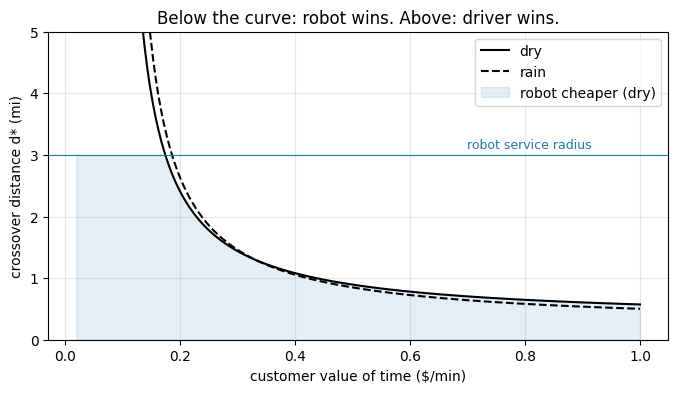

In [4]:
vots = np.linspace(0.02, 1.0, 200)
fig, ax = plt.subplots(figsize=(8, 4))
for rain, ls in ((False, "-"), (True, "--")):
    ax.plot(vots, [crossover_distance(rain=rain, value_of_time=v) for v in vots],
            "k", ls=ls, label="rain" if rain else "dry")
ax.axhline(ROBOT.max_range_mi, color="C0", lw=0.8)
ax.text(0.7, ROBOT.max_range_mi + 0.1, "robot service radius", color="C0", fontsize=9)
ax.fill_between(vots, 0, [min(crossover_distance(value_of_time=v), ROBOT.max_range_mi)
                          if np.isfinite(crossover_distance(value_of_time=v)) else ROBOT.max_range_mi
                          for v in vots], color="C0", alpha=0.12, label="robot cheaper (dry)")
ax.set(xlabel="customer value of time ($/min)", ylabel="crossover distance d* (mi)",
       ylim=(0, 5), title="Below the curve: robot wins. Above: driver wins.")
ax.legend(); ax.grid(alpha=0.3); plt.show()

# Part 3: Variability. Averages hide the 45-minute delivery.

Speeds aren't constant. Cars hit red lights and traffic, and robots hit crowded
sidewalks and curb cuts. Model speed as lognormal with coefficient of variation
$\text{CV}$, with parameters chosen so that $E[v]$ equals the nominal speed.

Since $t = t_0 + 60d/v$ and $1/v$ is convex, **Jensen's inequality** gives
$E[t] > t(E[v])$. Speed noise always makes the *average* trip longer, not just
more spread out.

sidewalk robot  rain=False  mean  30.1 min  (deterministic  27.7)  P(t > 30 min) = 0.45
sidewalk robot  rain=True   mean  39.4 min  (deterministic  36.3)  P(t > 30 min) = 0.80
human driver    rain=False  mean  12.6 min  (deterministic  12.0)  P(t > 30 min) = 0.00
human driver    rain=True   mean  13.7 min  (deterministic  13.1)  P(t > 30 min) = 0.00


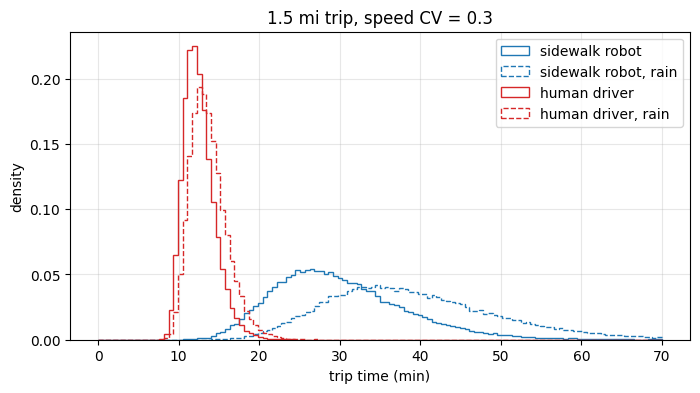

In [5]:
dist = 1.5
fig, ax = plt.subplots(figsize=(8, 4))
for c, col in ((ROBOT, "C0"), (DRIVER, "C3")):
    for rain, ls in ((False, "-"), (True, "--")):
        t = monte_carlo_trip_times(c, dist, rain=rain, n=50_000, speed_cv=0.3, seed=1)
        ax.hist(t, bins=120, range=(0, 70), histtype="step", color=col, ls=ls,
                density=True, label=f"{c.name}{', rain' if rain else ''}")
        print(f"{c.name:15s} rain={rain!s:5}  mean {t.mean():5.1f} min  "
              f"(deterministic {float(trip_time_min(c, dist, rain)):5.1f})  "
              f"P(t > 30 min) = {np.mean(t > 30):.2f}")
ax.set(xlabel="trip time (min)", ylabel="density", title=f"{dist} mi trip, speed CV = 0.3")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Rain availability.** Fleets often pause robots in heavy rain. Here
`ROBOT.rain_availability` = 0.6. If a paused order falls back to a driver after
a re-dispatch delay, the *expected* generalized cost of choosing the robot is

$$E[G] = p\,G_\text{robot} + (1-p)\big(G_\text{driver} + \text{VOT}\cdot t_\text{redispatch}\big)$$

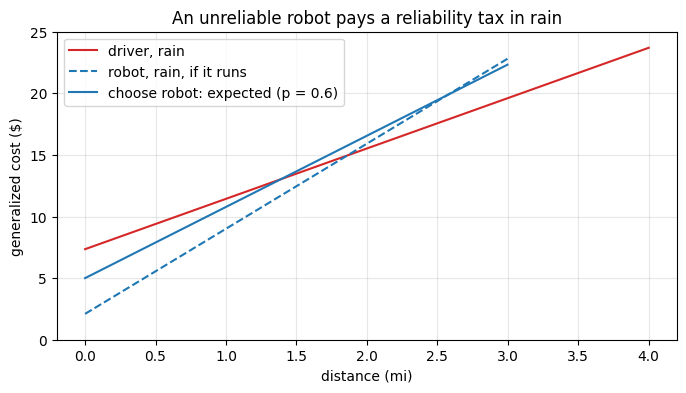

robot still worth choosing in rain for d < 1.38 mi


In [6]:
vot, t_re = 0.25, 8.0
p = ROBOT.rain_availability
Gr = trip_cost(ROBOT, d, rain=True, value_of_time=vot)
Gd = trip_cost(DRIVER, d, rain=True, value_of_time=vot)
EG = p * Gr + (1 - p) * (Gd + vot * t_re)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(d, Gd, "C3", label="driver, rain")
ax.plot(d, Gr, "C0", ls="--", label="robot, rain, if it runs")
ax.plot(d, EG, "C0", label=f"choose robot: expected (p = {p})")
ax.set(xlabel="distance (mi)", ylabel="generalized cost ($)", ylim=(0, 25),
       title="An unreliable robot pays a reliability tax in rain")
ax.legend(); ax.grid(alpha=0.3); plt.show()
ok = np.isfinite(EG) & (EG < Gd)
print(f"robot still worth choosing in rain for d < {d[ok].max():.2f} mi" if ok.any()
      else "robot never worth choosing in rain")

# Part 4: GPS error is two different noises

The robot needs to stay within about ±1 m of the sidewalk centerline. Phone-grade
GPS error has two parts:

- **White noise.** Independent from one fix to the next, $\sigma_w$. Averaging
  removes it.
- **Bias.** Multipath reflections off buildings that drift slowly. Modeled as
  first-order Gauss–Markov:
  $$b_{k+1} = \phi\,b_k + w_k,\quad \phi = e^{-\Delta t/\tau},\quad
  \operatorname{Var}(w) = \sigma_b^2(1-\phi^2)$$
  so the stationary standard deviation is exactly $\sigma_b$. With $\tau$ = 60 s,
  **averaging over seconds doesn't remove it.**

Urban canyons (tall buildings) raise both parts.

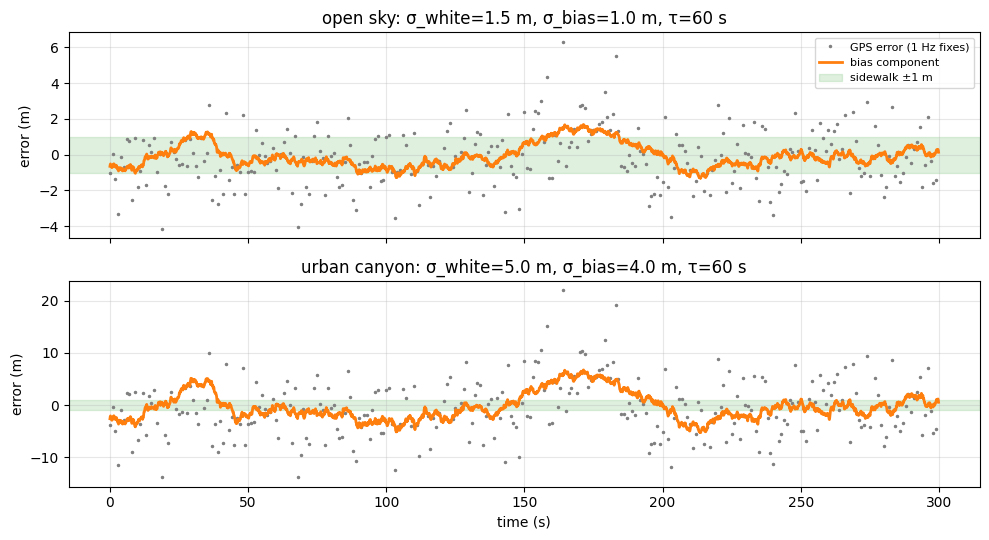

In [7]:
dt, T = 0.1, 300.0
n = int(T / dt); t = np.arange(n) * dt
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, (name, g) in zip(axes, (("open sky", GPS_OPEN_SKY), ("urban canyon", GPS_URBAN_CANYON))):
    e, b = gps_error(n, dt, seed=4, **g)
    ax.plot(t[::10], e[::10], ".", ms=3, color="0.5", label="GPS error (1 Hz fixes)")
    ax.plot(t, b, "C1", lw=2, label="bias component")
    ax.axhspan(-1, 1, color="C2", alpha=0.15, label="sidewalk ±1 m")
    ax.set(ylabel="error (m)", title=f"{name}: σ_white={g['sigma_white']} m, σ_bias={g['sigma_bias']} m, τ={g['tau_bias']:.0f} s")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="upper right"); axes[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

# Part 5: PID path following

**Plant (kinematic unicycle).** Here $y$ is the cross-track error, $\theta$ is the
heading relative to the sidewalk, and the command $u$ is the steering rate:

$$\dot\theta = u,\qquad \dot y = v\sin\theta \;\approx\; v\theta$$

Differentiating once more gives $\ddot y = v\,u$, a **double integrator**.

**Controller.** PD on the estimated error, with $u = -K_p\hat y - K_d\dot{\hat y}$.
The closed loop is

$$\ddot y + vK_d\,\dot y + vK_p\,y = 0 \;\Rightarrow\; \omega_n^2 = vK_p,\quad 2\zeta\omega_n = vK_d$$

With $v$ = 1.56 m/s and target $\omega_n$ = 0.5 rad/s, $\zeta$ = 0.8, this gives
$K_p \approx 0.16$ and $K_d \approx 0.51$. The defaults (0.14, 0.45) are close.
$K_i = 0$ because a double integrator has no steady-state offset to remove when
the reference is constant.

**Three estimators $\hat y$:**

| mode | what $\hat y$ is |
|---|---|
| `gps` | latest 1 Hz GPS fix, held constant between fixes |
| `fused` | scalar Kalman filter. Predict: $\hat y \mathrel{+}= v\sin\theta_\text{IMU}\,\Delta t$, $P \mathrel{+}= Q$. Update on each GPS fix: $K = P/(P+R)$ |
| `fused+vision` | same, plus a 10 Hz camera measurement of the curb ($\sigma$ = 10 cm, no bias) |

v = 1.56 m/s   design: Kp = 0.160, Kd = 0.511


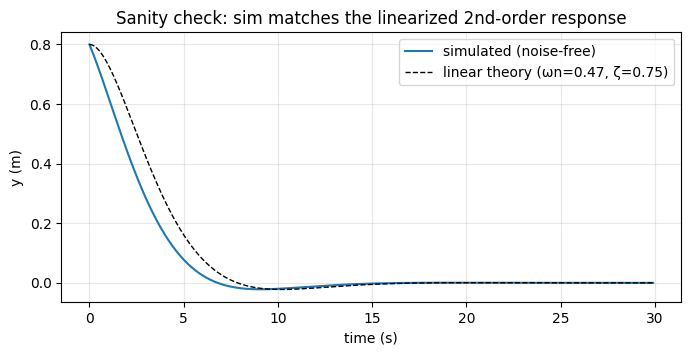

In [8]:
v = 3.5 * MPH_TO_MS
wn, zeta = 0.5, 0.8
print(f"v = {v:.2f} m/s   design: Kp = {wn**2/v:.3f}, Kd = {2*zeta*wn/v:.3f}")
s0 = simulate_path_following("fused+vision", gps=dict(sigma_white=0, sigma_bias=0, tau_bias=60),
                             sigma_heading=0, sigma_vision=1e-4, y0=0.8, T=30)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(s0["t"], s0["y"], label="simulated (noise-free)")
# analytic: underdamped 2nd-order from y0 with zero initial velocity
Kp, Kd = 0.14, 0.45
w0, z0 = np.sqrt(v*Kp), v*Kd/(2*np.sqrt(v*Kp)); wd = w0*np.sqrt(1-z0**2)
tt = s0["t"]
ax.plot(tt, 0.8*np.exp(-z0*w0*tt)*(np.cos(wd*tt) + z0*w0/wd*np.sin(wd*tt)), "k--", lw=1,
        label=f"linear theory (ωn={w0:.2f}, ζ={z0:.2f})")
ax.set(xlabel="time (s)", ylabel="y (m)", title="Sanity check: sim matches the linearized 2nd-order response")
ax.legend(); ax.grid(alpha=0.3); plt.show()

The simulation and the linear theory agree, apart from a small lag. That lag
comes from the one-step delay in the discrete PID derivative. Now add real sensors:

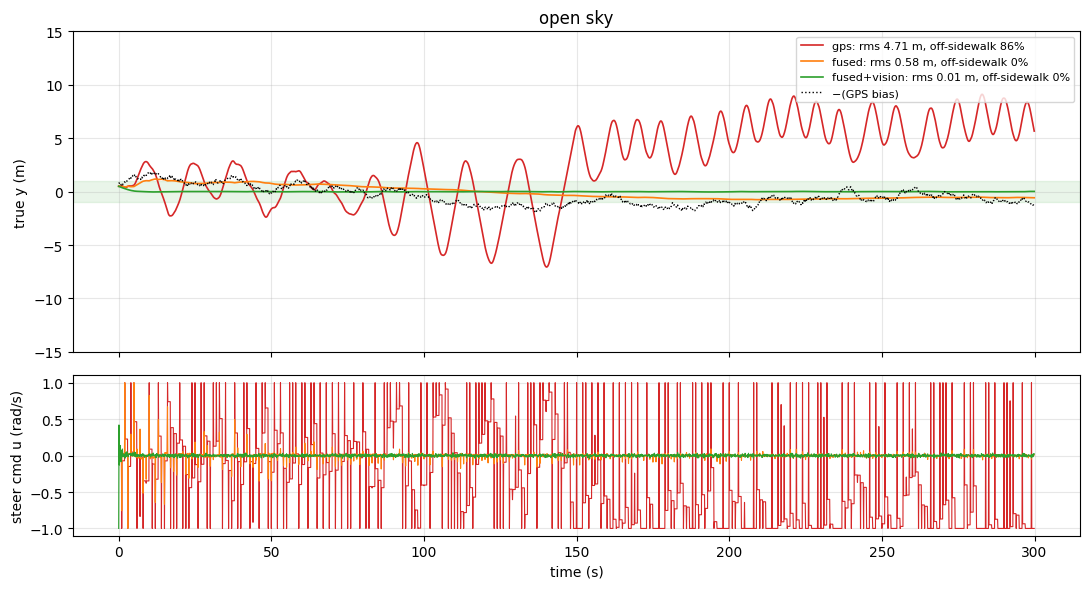

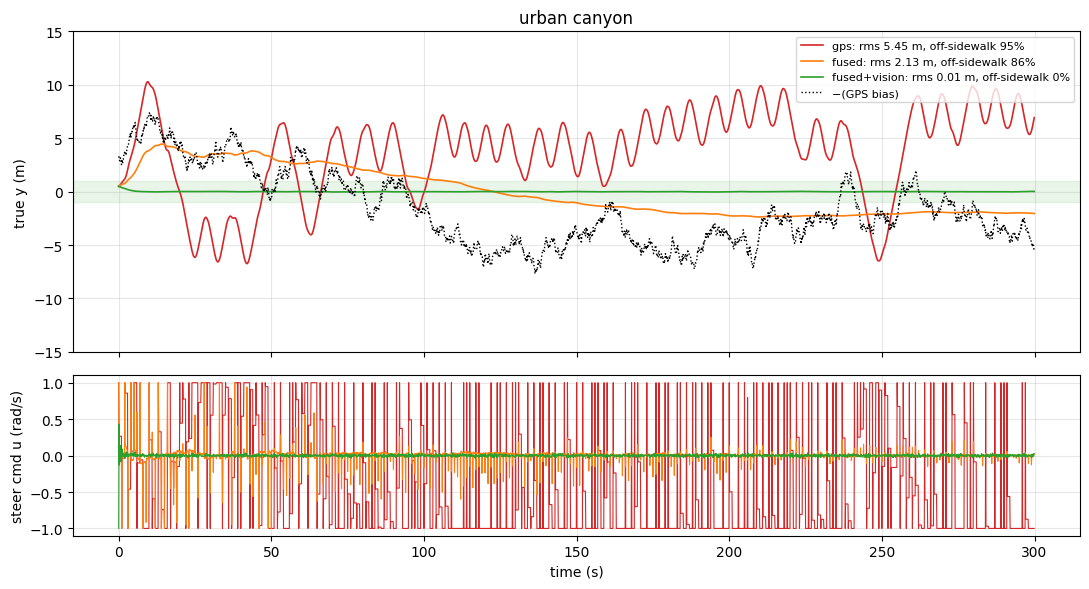

In [9]:
for env_name, g in (("open sky", GPS_OPEN_SKY), ("urban canyon", GPS_URBAN_CANYON)):
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                             gridspec_kw=dict(height_ratios=[2, 1]))
    for m, col in zip(MODES, ("C3", "C1", "C2")):
        s = simulate_path_following(m, gps=g, seed=5)
        axes[0].plot(s["t"], s["y"], col, lw=1.2,
                     label=f"{m}: rms {s['rms_y']:.2f} m, off-sidewalk {100*s['frac_off']:.0f}%")
        axes[1].plot(s["t"], s["u"], col, lw=0.8)
    axes[0].plot(s["t"], -s["gps_bias"], "k:", lw=1, label="−(GPS bias)")
    axes[0].axhspan(-1, 1, color="C2", alpha=0.1)
    axes[0].set(ylabel="true y (m)", title=f"{env_name}", ylim=(-15, 15))
    axes[0].legend(fontsize=8, loc="upper right"); axes[0].grid(alpha=0.3)
    axes[1].set(ylabel="steer cmd u (rad/s)", xlabel="time (s)"); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

**Three lessons from the plots.**

1. **Raw GPS plus a D term is a disaster.** Each new 1 Hz fix is a step in
   $\hat y$. The derivative of a step is a spike $\approx K_d\,\Delta y/\Delta t$
   (here $0.45 \times 5\,\text{m} / 0.1\,\text{s} \approx 22$ rad/s), so steering
   slams into its ±1 rad/s limit. Real controllers low-pass filter the D term, or
   take the derivative from a sensor that measures rate directly (here the IMU
   gives $\dot y = v\sin\theta$).
2. **The Kalman filter removes the white noise but follows the bias.** In the
   fused trace, the robot's true $y$ follows the dotted −bias line. It isn't
   noisy, it's *confidently wrong*. No sensor in the filter can observe the bias,
   so the filter has no way to subtract it. This is an **observability** problem,
   not a tuning problem.
3. **An independent absolute reference fixes it.** This is why sidewalk robots
   carry cameras and lidar and match against pre-built maps. Their precision
   comes from vision, not GPS. GPS only tells them which block they're on.

The rain connection: rain smears camera images and scatters lidar. That takes away
the one sensor that removes the bias, and it's why `rain_availability` < 1 for
the robot.

In [10]:
seeds = range(20)
print(f"{'environment':14s} {'mode':13s} {'rms y (m)':>10s} {'% off':>7s} {'% sat':>7s}")
for env_name, g in (("open sky", GPS_OPEN_SKY), ("urban canyon", GPS_URBAN_CANYON)):
    for m in MODES:
        r = [simulate_path_following(m, gps=g, seed=s) for s in seeds]
        print(f"{env_name:14s} {m:13s} {np.mean([x['rms_y'] for x in r]):10.2f} "
              f"{100*np.mean([x['frac_off'] for x in r]):7.1f} "
              f"{100*np.mean([x['frac_saturated'] for x in r]):7.1f}")

environment    mode           rms y (m)   % off   % sat
open sky       gps                 5.44    92.3    31.4


open sky       fused               0.72    22.3     0.0


open sky       fused+vision        0.01     0.0     0.0
urban canyon   gps                 8.28    93.5    59.3


urban canyon   fused               2.85    79.8     0.2


urban canyon   fused+vision        0.01     0.0     0.0


# Part 6: One year. From a free robot to more than \$10,000.

So far the robot's hardware has been hidden inside `cost_fixed`. Now pull it out
and ask a fleet-owner question: **if a robot costs \$P, how many deliveries a
year does it need to make before it beats paying drivers?**

1. Turn the purchase price into an equal yearly payment with the capital recovery
   factor (reused from [`dgs/engineering_economics.py`](../dgs/engineering_economics.py)):
   $$A = P\,\frac{i(1+i)^n}{(1+i)^n-1}\qquad(\;=P/n \text{ when } i=0)$$
2. Each robot trip saves $\Delta G(d) = G_\text{driver}(d) - G_\text{robot, marginal}(d)$.
   "Marginal" means `cost_fixed = 0`, so the hardware isn't counted twice.
3. Break-even trips per year:
   $$\boxed{N^\* = \frac{A}{\Delta G(d)}}$$
   This is linear in the price. A free robot pays off on its first trip.

There's also a physical ceiling. One robot can only fit so many round trips into
a 12-hour day, and if $N^\*$ is above that ceiling, it never pays off.

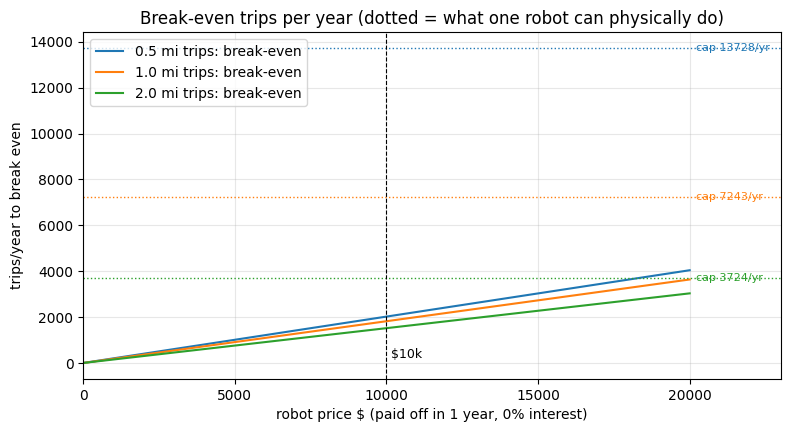

   price   0.5 mi     1 mi     2 mi   trips/day at 1 mi
$      0        0        0        0      0.0
$  1,000      202      182      152      0.5
$  5,000     1010      910      758      2.5
$ 10,000     2021     1819     1517      5.0
$ 15,000     3031     2729     2275      7.5
$ 20,000     4042     3639     3034     10.0

$10k robot, life 1 yr, i = 0%:  A = $ 10,000/yr  ->  N* =  1819 trips/yr =  5.0/day at 1 mi
$10k robot, life 3 yr, i = 0%:  A = $  3,333/yr  ->  N* =   606 trips/yr =  1.7/day at 1 mi
$10k robot, life 3 yr, i = 8%:  A = $  3,880/yr  ->  N* =   706 trips/yr =  1.9/day at 1 mi
$10k robot, life 5 yr, i = 8%:  A = $  2,505/yr  ->  N* =   456 trips/yr =  1.2/day at 1 mi


In [11]:
from dgs.delivery_robot_vs_driver import annual_breakeven_trips, max_trips_per_year
from dgs.engineering_economics import capital_recovery_factor

prices = np.linspace(0, 20_000, 201)
fig, ax = plt.subplots(figsize=(9, 4.5))
for dist, col in ((0.5, "C0"), (1.0, "C1"), (2.0, "C2")):
    N = [annual_breakeven_trips(P, dist) for P in prices]
    ax.plot(prices, N, col, label=f"{dist} mi trips: break-even")
    cap = max_trips_per_year(dist)
    ax.axhline(cap, color=col, ls=":", lw=1)
    ax.text(20_200, cap, f"cap {cap:.0f}/yr", color=col, fontsize=8, va="center")
ax.axvline(10_000, color="k", lw=0.8, ls="--"); ax.text(10_150, 200, "$10k", fontsize=9)
ax.set(xlabel="robot price $ (paid off in 1 year, 0% interest)",
       ylabel="trips/year to break even", xlim=(0, 23_000),
       title="Break-even trips per year (dotted = what one robot can physically do)")
ax.legend(loc="upper left"); ax.grid(alpha=0.3); plt.show()

print(f"{'price':>8s} {'0.5 mi':>8s} {'1 mi':>8s} {'2 mi':>8s}   trips/day at 1 mi")
for P in (0, 1_000, 5_000, 10_000, 15_000, 20_000):
    n = [annual_breakeven_trips(P, x) for x in (0.5, 1.0, 2.0)]
    print(f"${P:>7,} {n[0]:8.0f} {n[1]:8.0f} {n[2]:8.0f}   {n[1]/365:6.1f}")

print()
for life, i in ((1, 0.0), (3, 0.0), (3, 0.08), (5, 0.08)):
    A = capital_recovery_factor(10_000, i, life)
    N = annual_breakeven_trips(10_000, 1.0, life_years=life, interest=i)
    print(f"$10k robot, life {life} yr, i = {i:.0%}:  A = ${A:7,.0f}/yr  ->  "
          f"N* = {N:5.0f} trips/yr = {N/365:4.1f}/day at 1 mi")

**How to read this.** A \$10,000 robot that has to pay for itself in a single year
needs about 1,800 one-mile deliveries, roughly 5 a day. That's well under the
roughly 7,000 a year it could physically make. Spread the cost over 3–5 years
and the requirement drops to 1–2 trips a day.

So the hardware price isn't what holds robots back. What holds them back is
**demand density**: having enough short orders inside the robot's ~3 mi radius to
keep it busy. Uptime matters too: rain, broken robots, recharging.

# Part 7: Hills and cracks

**Hills.** A robot's motors can only deliver so much power. At constant speed on
a slope $\alpha = \arctan(\text{grade})$, the motor power has to balance gravity
plus rolling resistance:

$$P = m g\,(\sin\alpha + C_{rr}\cos\alpha)\,v \;\Rightarrow\; v = \frac{P}{mg(\sin\alpha + C_{rr}\cos\alpha)}$$

The result is capped at the design speed. Climbing also costs battery energy,
$E = mgh/\eta$, regardless of how steep the slope is.

**Cracks and curbs.** To push a wheel of radius $r$ over a step of height $h$,
take torques about the step's edge. With the push applied horizontally at the axle:

$$\frac{F}{W} = \frac{\sqrt{h(2r-h)}}{r-h}$$

This goes to infinity as $h \to r$. A wheel can never climb a step taller than
its radius, and in practice it struggles well before that.

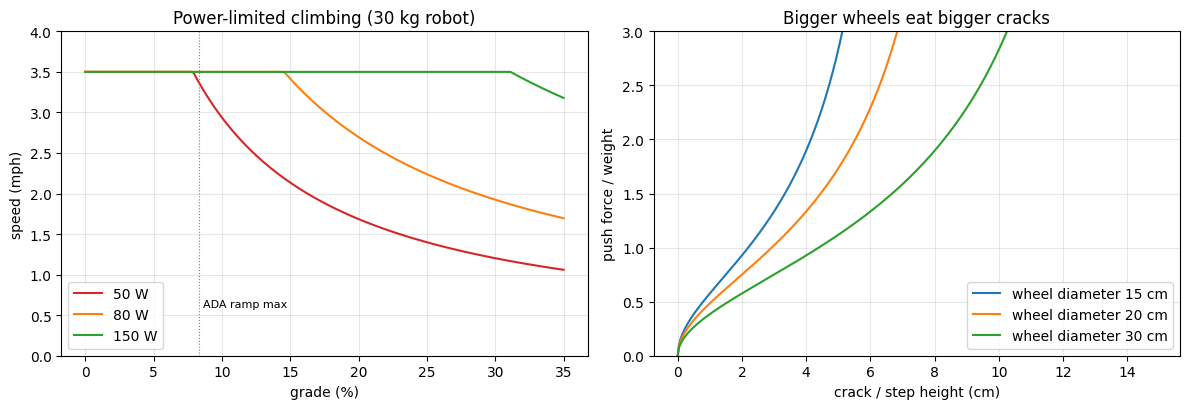

climb  10 m:   1.2 Wh of battery
climb  30 m:   3.5 Wh of battery
climb  60 m:   7.0 Wh of battery
F/W for a 3 cm heave with 20 cm wheels: 1.02


In [12]:
from dgs.delivery_robot_vs_driver import hill_speed, climb_energy_wh, step_force_ratio

grades = np.linspace(0, 0.35, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for P, col in ((50, "C3"), (80, "C1"), (150, "C2")):
    axes[0].plot(100*grades, hill_speed(grades, power_w=P) / MPH_TO_MS, col, label=f"{P} W")
axes[0].axvline(8.33, color="0.5", lw=0.8, ls=":")
axes[0].text(8.6, 0.6, "ADA ramp max", fontsize=8)
axes[0].set(xlabel="grade (%)", ylabel="speed (mph)", ylim=(0, 4),
            title="Power-limited climbing (30 kg robot)")
axes[0].legend(); axes[0].grid(alpha=0.3)

h = np.linspace(0, 0.149, 400)
for D, col in ((0.15, "C0"), (0.20, "C1"), (0.30, "C2")):
    hh = h[h < D/2]
    axes[1].plot(100*hh, step_force_ratio(hh, D), col, label=f"wheel diameter {100*D:.0f} cm")
axes[1].set(xlabel="crack / step height (cm)", ylabel="push force / weight", ylim=(0, 3),
            title="Bigger wheels eat bigger cracks")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

for rise in (10, 30, 60):
    print(f"climb {rise:3d} m: {float(climb_energy_wh(rise)):5.1f} Wh of battery")
print(f"F/W for a 3 cm heave with 20 cm wheels: {float(step_force_ratio(0.03, 0.20)):.2f}")

A 30 kg robot climbing a 30 m hill uses only about 3.5 Wh, a few percent of a
typical battery pack. **Hills hurt the robot's speed, not its range.** Cracks are
the worse problem: a 3 cm sidewalk heave needs a push of about 1× the robot's
own weight with 20 cm wheels. That's why sidewalk robots use 6 wheels on rocker
suspension instead of 4.

# Part 8: Shoe, bike, ski, robot, car. Kinetic energy and velocity vectors.

$$KE = \tfrac12 m|\vec v|^2$$

$KE$ grows with the *square* of speed but only linearly with mass. Doubling speed
quadruples the energy.

**What a collision actually does damage with.** In a perfectly inelastic collision
(the two bodies end up moving together), momentum $\vec p = m_1\vec v_1 + m_2\vec v_2$
is conserved. The centre-of-mass motion survives, and **only the relative motion
is destroyed**:

$$\Delta KE = \tfrac12\,\mu\,|\vec v_1 - \vec v_2|^2,\qquad \mu = \frac{m_1 m_2}{m_1+m_2}$$

Two consequences:

- **Relative velocity is a vector.** Two skiers going the same direction at the
  same speed have $\vec v_1-\vec v_2 = 0$, so a bump destroys no energy. A
  head-on collision destroys the most. The crossing angle matters.
- **The reduced mass is capped by the lighter body.** When a 1,500 kg car hits
  a 70 kg pedestrian, $\mu \approx 67$ kg. The energy that does damage is about
  $\tfrac12 m_\text{ped} v^2$, *not* the car's 94 kJ. **What hurts the pedestrian
  is that they're suddenly moving at the car's speed.** The car's mass barely
  enters, which is why speed limits matter more than vehicle size for
  pedestrian injuries.

mover              mass    speed         KE   into a standing walker
walker (shoes)      70kg   3.1mph        69 J                    34 J
sidewalk robot      30kg   3.5mph        37 J                    26 J
bike                85kg  13.4mph     1,530 J                   691 J
skier               80kg  26.8mph     5,760 J                 2,688 J
car @ 25 mph      1500kg  25.0mph    93,677 J                 4,177 J


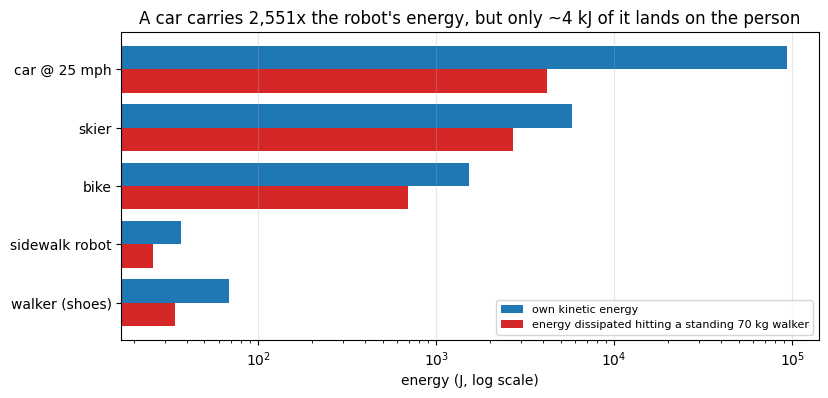

In [13]:
from dgs.delivery_robot_vs_driver import MOVERS, kinetic_energy, collision_energy, velocity_vector

m_ped = 70.0
print(f"{'mover':16s} {'mass':>6s} {'speed':>8s} {'KE':>10s} {'into a standing walker':>24s}")
names, ke, hit = [], [], []
for name, (m, v) in MOVERS.items():
    k = kinetic_energy(m, v)
    e = collision_energy(m, velocity_vector(v, 0), m_ped, [0, 0])
    names.append(name); ke.append(k); hit.append(e)
    print(f"{name:16s} {m:5.0f}kg {v/MPH_TO_MS:5.1f}mph {k:9,.0f} J {e:21,.0f} J")

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(names))
ax.barh(y + 0.2, ke, 0.4, label="own kinetic energy", color="C0")
ax.barh(y - 0.2, hit, 0.4, label="energy dissipated hitting a standing 70 kg walker", color="C3")
ax.set_yticks(y, names); ax.set_xscale("log"); ax.set_xlabel("energy (J, log scale)")
ax.set_title(f"A car carries {ke[-1]/ke[1]:,.0f}x the robot's energy, "
             f"but only ~{hit[-1]/1000:.0f} kJ of it lands on the person")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="x"); plt.show()

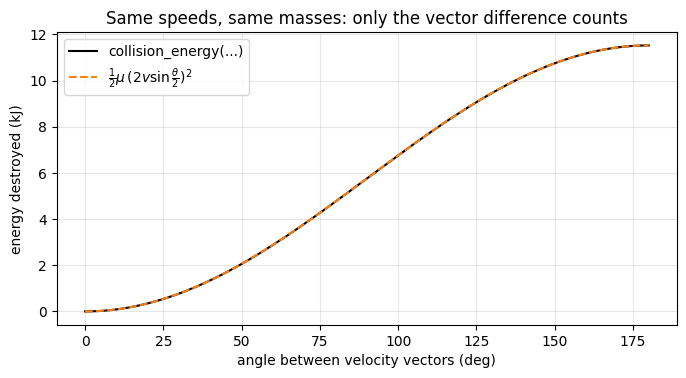

In [14]:
# Same two skiers (80 kg, 12 m/s), different crossing angles
angles = np.linspace(0, 180, 181)
m, v = MOVERS["skier"]
E = [collision_energy(m, velocity_vector(v, 0), m, velocity_vector(v, a)) for a in angles]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(angles, np.array(E) / 1000, "k", label="collision_energy(...)")
ax.plot(angles, 0.5 * (m/2) * (2*v*np.sin(np.radians(angles)/2))**2 / 1000, "C1--", lw=1.5,
        label=r"$\frac{1}{2}\mu\,(2v\sin\frac{\theta}{2})^2$")
ax.set(xlabel="angle between velocity vectors (deg)", ylabel="energy destroyed (kJ)",
       title="Same speeds, same masses: only the vector difference counts")
ax.legend(); ax.grid(alpha=0.3); plt.show()

The skier curve follows $|\vec v_1-\vec v_2| = 2v\sin(\theta/2)$ from the law of
cosines. At 0° nothing happens. At 90° half the maximum is destroyed. At 180°
(head-on) all of the kinetic energy is.

For the robot: at 3.5 mph and 30 kg, hitting someone deposits about 25 J,
roughly a backpack swung into your shin. The car deposits about 4,000 J. That
160× gap is why robots are allowed on sidewalks and cars are not.

# Summary

| | robot wins | driver wins |
|---|---|---|
| **time** | trips under ~0.3 mi (≈500 m) | everything longer |
| **operator cost** | everywhere within range | — |
| **generalized cost** | $d < d^\*$, which shrinks as the customer values time more | $d > d^\*$ or beyond the service radius |
| **rain** | — | the robot gets slower, gets paused, and loses its vision sensor |
| **dense downtown** | only with vision localization | GPS errors don't matter much to a human |
| **1-year payback** | a \$10k robot needs ~5 one-mile trips/day | — |
| **hills / cracks** | hills cost speed, not range | cracks over ~⅓ of the wheel diameter |
| **safety** | ~25 J into a pedestrian | ~4,000 J at 25 mph |

The best fit for robots is campuses and dense suburbs: short trips, cheap labor
substitution, open sky, mild weather. That's also where the real deployments
started.

## Exercises

1. Set `DRIVER = replace(DRIVER, rain_cost_factor=1.0)` (no surge pay). How far
   does the rain crossover move?
2. Add a low-pass filter on the D term in `gps` mode
   ($\dot{\hat y}_f \leftarrow \alpha\dot{\hat y}_f + (1-\alpha)\dot{\hat y}$).
   What value of $\alpha$ stops the saturation?
3. Make the bias observable: give the Kalman filter a 2-state vector
   $[y, b]$ and a second GPS antenna, or a known landmark every 50 m. Does
   `fused` approach `fused+vision`?
4. Re-derive $K_p, K_d$ for a robot running at 6 mph. Why must the gains *drop*
   as $v$ rises? Hint: the plant gain is $v$.
5. Unit check: confirm $60\,d/v$ has units of minutes when $d$ is in miles and
   $v$ is in mph.
6. At what car speed does the energy put into a pedestrian equal that of a
   12 m/s skier hitting a standing walker? Solve $\tfrac12\mu v^2$ = target for $v$.
7. Raise the interest rate to 15%. How many trips per day does a \$15k
   robot with a 3-year life need at 2 mi?